In [5]:
import pandas as pd
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from os import listdir

In [6]:
# 1. SETTINGS & PATHS
img_height, img_width = 224, 224

# Original training and validation paths
train_paths = [
    '/kaggle/input/plant-village-dataset-updated/Apple/Train', 
    '/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset/train'
]
val_paths = [
    '/kaggle/input/plant-village-dataset-updated/Apple/Val', 
    '/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset/test'
]

# 960px Plant Pathology 2021 paths
pp_csv = '/kaggle/input/datasets/jirkaborovec/plant-pathology-2021-fgvc8-960px/train.csv'
pp_img_dir = '/kaggle/input/datasets/jirkaborovec/plant-pathology-2021-fgvc8-960px/train_images'

# New Non Leaf Path
non_leaf_dir = '/kaggle/input/datasets/robiulhasanjisan/leaf-vs-non-leaf-images/non_leaf'

test_directory = r'/kaggle/input/plant-village-dataset-updated/Apple/Test'

# 2. DATA COLLECTION MAPPING
dataset_map = {
    'Apple Scab': ['Apple Scab', 'Apple_Scab_Leaf'],
    'Black Rot': ['Black Rot'], 
    'Cedar Apple Rust': ['Cedar Apple Rust', 'Apple_rust_leaf'],
    'Healthy': ['Healthy', 'Apple_leaf'] 
}

def collect_data(paths_list):
    data = []
    for base_path in paths_list:
        is_plantdoc = 'plantdoc' in base_path.lower()
        for root, dirs, files in os.walk(base_path):
            folder_name = os.path.basename(root)
            for target_label, search_folders in dataset_map.items():
                if folder_name in search_folders:
                    # Constraint: Black Rot must NOT come from PlantDoc
                    if target_label == 'Black Rot' and is_plantdoc:
                        continue
                        
                    for img_name in files:
                        if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                            data.append({'path': os.path.join(root, img_name), 'label': target_label})
    return data

# Initial gathering from PV and PD
train_list = collect_data(train_paths)
val_list = collect_data(val_paths)

# 3. INJECT PP2021 DATA
if os.path.exists(pp_csv):
    df_pp = pd.read_csv(pp_csv)
    pp_map = {
        'frog_eye_leaf_spot': 'Black Rot', 
        'rust': 'Cedar Apple Rust', 
        'scab': 'Apple Scab',
        'healthy': 'Healthy'
    }
    
    for pp_label, target_label in pp_map.items():
        filtered = df_pp[df_pp['labels'] == pp_label].copy()
        for img_name in filtered['image']:
            train_list.append({
                'path': os.path.join(pp_img_dir, img_name), 
                'label': target_label
            })

# 4. INJECT NON LEAF DATA (Manual Split)
non_leaf_data = []
if os.path.exists(non_leaf_dir):
    for img_name in os.listdir(non_leaf_dir):
        if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
            non_leaf_data.append({
                'path': os.path.join(non_leaf_dir, img_name), 
                'label': 'Non Leaf'
            })

# Split Non Leaf 85/15 into train and validation
nl_train, nl_val = train_test_split(non_leaf_data, test_size=0.15, random_state=42)
train_list.extend(nl_train)
val_list.extend(nl_val)

# 5. THE "EQUALIZER" (Truncating to the lowest class count)
full_df = pd.DataFrame(train_list)

# Get counts and find the minimum to truncate all 5 classes
class_counts = full_df['label'].value_counts()
min_size = class_counts.min() 

print("Initial Counts before Balancing (5 Classes):")
print(class_counts)

# Sample each class to match the size of the smallest class
balanced_df = pd.concat([
    full_df[full_df['label'] == label].sample(min_size, random_state=42) 
    for label in full_df['label'].unique()
])

# Shuffle the balanced training data
train_df = balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)
# Form the validation dataframe from the accumulated validation list
valid_df = pd.DataFrame(val_list).sample(frac=1, random_state=42).reset_index(drop=True)

print("\n--- FINAL BALANCED 5-CLASS DISTRIBUTION ---")
print(train_df['label'].value_counts())

Initial Counts before Balancing (5 Classes):
label
Apple Scab          6925
Healthy             6711
Non Leaf            5525
Black Rot           5168
Cedar Apple Rust    1856
Name: count, dtype: int64

--- FINAL BALANCED 5-CLASS DISTRIBUTION ---
label
Healthy             1856
Cedar Apple Rust    1856
Apple Scab          1856
Non Leaf            1856
Black Rot           1856
Name: count, dtype: int64


In [7]:
train_datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.85, 1.15],
    fill_mode='nearest'
)

# No augmentation for validation, strictly evaluation
valid_datagen = ImageDataGenerator()

test_datagen = ImageDataGenerator()

In [8]:
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df, x_col='path', y_col='label',
    target_size=(img_height, img_width), batch_size=32,
    class_mode='sparse', color_mode='rgb'
)

valid_gen = valid_datagen.flow_from_dataframe(
    dataframe=valid_df, x_col='path', y_col='label',
    target_size=(img_height, img_width), batch_size=32,
    class_mode='sparse', color_mode='rgb',
    shuffle=False) # Keep False to align predictions with filenames later if needed

test_gen = test_datagen.flow_from_directory(test_directory,
                                            target_size = (224, 224),
                                            batch_size = 32,
                                            class_mode ='sparse',
                                            color_mode = 'rgb',
                                            shuffle=False)  # Keep False to easily map predictions to filenames

Found 9280 validated image filenames belonging to 5 classes.
Found 2751 validated image filenames belonging to 5 classes.
Found 196 images belonging to 4 classes.


In [9]:
len(train_gen.class_indices)

5

In [10]:
from tensorflow import keras
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model, Sequential

# 4. MODEL ARCHITECTURE
base_model = MobileNetV2(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=False)
base_model.trainable = False

model = Sequential()

model.add(Lambda(preprocess_input, input_shape=(img_height, img_width, 3), name='preprocessing'))
model.add(base_model)
model.add(GlobalAveragePooling2D())
model.add(Dropout(0.5))
model.add(Dense(len(train_gen.class_indices), activation='softmax'))
model.summary()

I0000 00:00:1777026619.800916      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777026619.807033      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/lambda_layer.py:65: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocessing (Lambda)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# ModelCheckpoint to save model in case of 
# interrupting the learning process
checkpoint = ModelCheckpoint("./Apple_Augmented_5_Classes.keras",
                             monitor = "val_loss",
                             mode = "min",
                             save_best_only = True,
                             verbose = 1)

# EarlyStopping to find best model with a large number of epochs
earlystop = EarlyStopping(monitor = 'val_loss',
                          restore_best_weights = True,
                          patience = 3,  # number of epochs with 
                          mode = 'min',             # no improvement after which 
                                       # training will be stopped
                          verbose=1)

callbacks = [earlystop, checkpoint]
model.compile(loss = 'sparse_categorical_crossentropy',
                        optimizer = Adam(learning_rate=0.0001),
                        metrics = ['accuracy'])

In [12]:
epochs = 10

history = model.fit(
    train_gen,
    epochs = epochs,
    callbacks = [callbacks],
    validation_data = valid_gen,
    steps_per_epoch = len(train_gen))

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1777026628.279752     134 service.cc:152] XLA service 0x7b90480050e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777026628.279788     134 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777026628.279792     134 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777026629.318042     134 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-24 10:30:37.093226: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-24 10:30:37.229148: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1777026639.272510     134 device_co

 76/290 ━━━━━━━━━━━━━━━━━━━━ 2:06 592ms/step - accuracy: 0.2440 - loss: 2.1860

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 593ms/step - accuracy: 0.3073 - loss: 1.8791

2026-04-24 10:34:08.600476: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-24 10:34:08.737373: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from inf to 0.92331, saving model to ./Apple_Augmented_5_Classes.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 228s 732ms/step - accuracy: 0.3076 - loss: 1.8780 - val_accuracy: 0.6412 - val_loss: 0.9233
Epoch 2/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.5728 - loss: 1.0773
Epoch 2: val_loss improved from 0.92331 to 0.63393, saving model to ./Apple_Augmented_5_Classes.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 142s 490ms/step - accuracy: 0.5729 - loss: 1.0771 - val_accuracy: 0.7808 - val_loss: 0.6339
Epoch 3/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.6527 - loss: 0.8723
Epoch 3: val_loss improved from 0.63393 to 0.47953, saving model to ./Apple_Augmented_5_Classes.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 142s 490ms/step - accuracy: 0.6527 - loss: 0.8722 - val_accuracy: 0.8615 - val_loss: 0.4795
Epoch 4/10
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step - accuracy: 0.7033 - loss: 0.7309
Epoch 4: val_loss improved from 0.47953 to 0.38749, saving model to ./

In [13]:
base_model.trainable = True
for layer in base_model.layers[:-100]: # Unfreeze 100 layers to improve feature granularity
    layer.trainable = False

In [14]:
model.compile(loss = 'sparse_categorical_crossentropy',
                        optimizer = Adam(learning_rate=0.0001),
                        metrics = ['accuracy'])

epochs = 40

history = model.fit(
    train_gen,
    epochs = epochs,
    callbacks = [callbacks],
    validation_data = valid_gen,
    steps_per_epoch = len(train_gen))

model.save('./Apple_Augmented_5_Classes.keras')

Epoch 1/40
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.7923 - loss: 0.7402
Epoch 1: val_loss improved from 0.20382 to 0.09000, saving model to ./Apple_Augmented_5_Classes.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 182s 521ms/step - accuracy: 0.7926 - loss: 0.7389 - val_accuracy: 0.9720 - val_loss: 0.0900
Epoch 2/40
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.9535 - loss: 0.1309
Epoch 2: val_loss improved from 0.09000 to 0.04539, saving model to ./Apple_Augmented_5_Classes.keras
290/290 ━━━━━━━━━━━━━━━━━━━━ 143s 492ms/step - accuracy: 0.9535 - loss: 0.1309 - val_accuracy: 0.9891 - val_loss: 0.0454
Epoch 3/40
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 450ms/step - accuracy: 0.9606 - loss: 0.1058
Epoch 3: val_loss did not improve from 0.04539
290/290 ━━━━━━━━━━━━━━━━━━━━ 143s 492ms/step - accuracy: 0.9606 - loss: 0.1057 - val_accuracy: 0.9920 - val_loss: 0.0455
Epoch 4/40
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 450ms/step - accuracy: 0.9703 - loss: 0.0832
Epoch 4: val_loss did not improve 

In [15]:
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

6/7 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.9872 - loss: 0.0170

2026-04-24 11:22:44.337540: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-24 11:22:44.472675: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-24 11:22:44.607413: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.9892 - loss: 0.0150 
Test Accuracy: 99.49%
Test Loss: 0.0092


7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 709ms/step


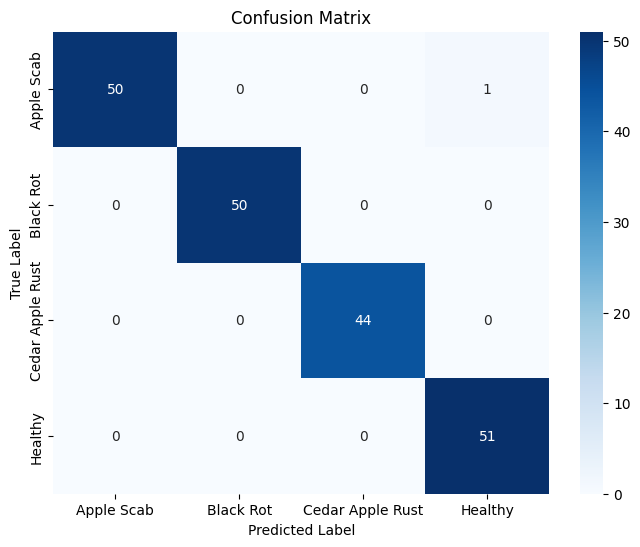

                  precision    recall  f1-score   support

      Apple Scab       1.00      0.98      0.99        51
       Black Rot       1.00      1.00      1.00        50
Cedar Apple Rust       1.00      1.00      1.00        44
         Healthy       0.98      1.00      0.99        51

        accuracy                           0.99       196
       macro avg       1.00      1.00      1.00       196
    weighted avg       0.99      0.99      0.99       196



In [16]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions
predictions = model.predict(test_gen)
y_pred = np.argmax(predictions, axis=1)
y_true = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# Plotting the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Detailed Report (Precision, Recall, F1-Score)
print(classification_report(y_true, y_pred, target_names=class_labels))

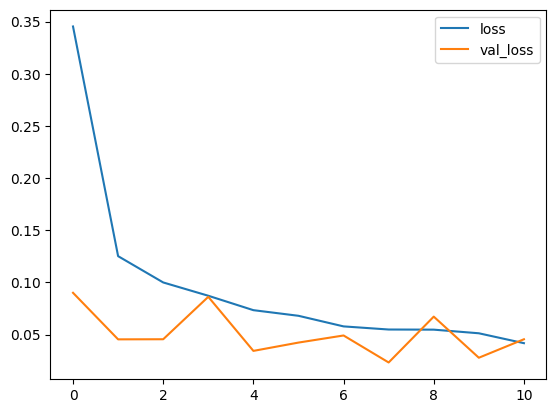

In [17]:
history_df = pd.DataFrame(history.history)

plt.plot(history_df.loc[ : , 'loss',], label = 'loss')
plt.plot(history_df.loc[ : , 'val_loss'], label = 'val_loss')

plt.legend()
plt.show()

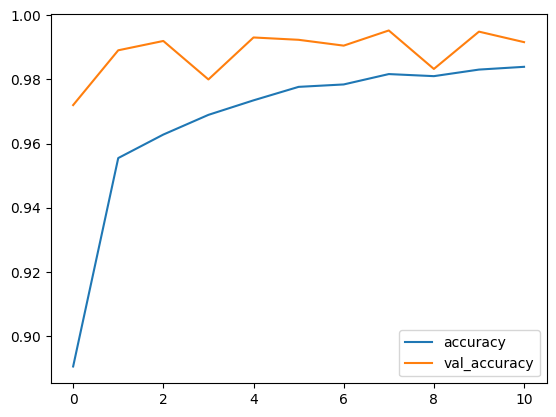

In [18]:
plt.plot(history_df.loc[ : , 'accuracy',], label = 'accuracy')
plt.plot(history_df.loc[ : , 'val_accuracy'], label = 'val_accuracy')

plt.legend()
plt.show()

In [19]:
import os
import tensorflow as tf

# 1. Load the model from your specific path
model_path = './Apple_Augmented_5_Classes.keras'
custom_objects = {'preprocess_input': preprocess_input}

# Load the model with the mapping
model = tf.keras.models.load_model('./Apple_Augmented_5_Classes.keras', custom_objects=custom_objects)

# 2. Initialize the converter
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 3. Floating Point is the DEFAULT (don't add optimization flags here)
# To help fix the v12 error, ensure we only use standard TFLite built-in ops
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]

# 4. Convert and Save
tflite_model = converter.convert()

with open('Apple_Augmented_5_Classes.tflite', 'wb') as f:
    f.write(tflite_model)

tflite_path = './Apple_Augmented_5_Classes.tflite'

    # 4. Compare file sizes
keras_size = os.path.getsize(model_path) / (1024 * 1024)
tflite_size = os.path.getsize(tflite_path) / (1024 * 1024)

print(f"✅ Success! TFLite model saved to: {tflite_path}")
print(f"📊 Keras Model Size: {keras_size:.2f} MB")
print(f"📉 TFLite Model Size: {tflite_size:.2f} MB")

print(f"❌ Error: {model_path} not found. Check your previous saving step.")

INFO:tensorflow:Assets written to: /tmp/tmpkfv6_a_7/assets


INFO:tensorflow:Assets written to: /tmp/tmpkfv6_a_7/assets


Saved artifact at '/tmp/tmpkfv6_a_7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  135862816310096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862817184208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862817184016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862813716368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862813720016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862812396240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862812403152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862812393744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862812396048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135862812404496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1358628124037

W0000 00:00:1777029785.113598      55 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1777029785.113632      55 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1777029785.245719      55 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled


In [20]:
labels = '\n'.join(sorted(train_gen.class_indices.keys()))

with open('./Apple_Augmented_5_Classes_labels.txt', 'w') as f:
    f.write(labels)

In [21]:
files_to_keep = ['./Apple_Augmented_5_Classes.keras', './Apple_Augmented_5_Classes.tflite', './Apple_Augmented_5_Classes_labels.txt']

print("--- Final File Check ---")
for file in files_to_keep:
    if os.path.exists(file):
        size = os.path.getsize(file) / 1024
        print(f"✅ Found: {file} ({size:.2f} KB)")
    else:
        print(f"❌ Missing: {file}")

--- Final File Check ---
✅ Found: ./Apple_Augmented_5_Classes.keras (26484.33 KB)
✅ Found: ./Apple_Augmented_5_Classes.tflite (8677.18 KB)
✅ Found: ./Apple_Augmented_5_Classes_labels.txt (0.05 KB)
